# Proyecto 1: Mapeo Robótico con Datos LiDAR

## Bienvenido al mundo de las Transformaciones Lineales

En este proyecto te ayudaremos a experimentar cuán poderosa es el álgebra matricial para manejar grandes (**ENORMES**) cantidades de datos.

---

## Código de Honor

- Puedes realizar preguntas generales en TELEGRAM.
- Si tu notebook se bloquea por alguna razón, definitivamente puedes avisarnos en TELEGRAM.
- No publiques código, respuestas ni imágenes en Piazza.
- No trabajes con otras personas, con excepción de un IA, asistente o profesor del curso.
- Al enviar este proyecto, certificas que representa tu propio trabajo y no el trabajo de otra persona.


## Tarea 0 (0 Puntos)

Esta tarea es un calentamiento sobre operaciones con vectores y matrices. Nada anterior a la Tarea 1 será calificado.

- Sea $A$ una matriz de tamaño $n \times m$
- `size(A,1)` devuelve $n$, el número de filas de $A$
- `size(A,2)` devuelve $m$, el número de columnas de $A$
- `size(A)` por sí solo devuelve $n, m$, una tupla de 2 elementos con el número de filas primero y el número de columnas después
- `length(A)` devuelve $n \times m$, es decir, el número total de elementos de $A$

- Sea $v$ un vector de dimensión $n$, que en clase llamamos vector columna, o una matriz $1 \times n$, que en clase llamamos vector fila
- `length(v)` devuelve $n$, el número de elementos de $v$
- Aunque puedes aplicar el comando `size` a un vector, generalmente es un error hacerlo. Es mucho más recomendable utilizar el comando `length`

### Importante

Es muy poco frecuente que necesites el número total de elementos de una matriz. Casi siempre querrás:

- el número de filas **Y** el número de columnas, o
- únicamente el número de filas **O** el número de columnas.

In [3]:
% Ejecutar esta celda. Crea algunos datos para experimentar

rand("seed", 101);
randn("seed", 101);

A = randn(3,4);
B = randn(4,10);

v3 = [1; 2; 3.0];
v4 = [1; 2; 3; 4.0];

In [4]:
# número de filas y columnas de una matriz
#
# descomenta la siguiente línea y completa el comando
# para obtener el número de filas y columnas de la matriz A
#
# nRows, nCols = ???
[nRows, nCols] = size(A);

if isequal([nRows nCols], [3 4])
    disp("Correcto: A tiene 3 filas y 4 columnas.")
    
elseif isequal([nRows nCols], [4 3])
    disp("Invertiste filas y columnas. Probablemente usaste [nCols nRows].")
    
else
    disp("Algo salió mal. Revisa nuevamente size(A).")
end

Correcto: A tiene 3 filas y 4 columnas.


In [6]:
# si SOLO quieres el número de columnas de una matriz y no necesitas las filas
#
# descomenta la siguiente línea y completa el comando para obtener ÚNICAMENTE
# el número de columnas de la matriz B
#
# nColsB = ??

nColsB = size(B,2)

# verificación rápida
if nColsB == 10
    disp("Correcto. Vas muy bien.")
    
elseif nColsB == 40
    disp("Parece que usaste el comando length, lo cual es incorrecto. Revisa nuevamente la diferencia entre size y length en el Manual de Laboratorio.")
    
elseif nColsB == 3
    disp("Incorrecto. Has confundido filas con columnas.")
    
else
    disp("No podemos identificar el origen del error, pero inténtalo nuevamente.")
end

if exist('nRowsB','var')
    disp("Debiste haber usado [nRowsB, nColsB] = size(B). Queríamos que utilizaras únicamente nColsB = size(B,2)")
end

nColsB = 10


Correcto. Vas muy bien.


In [7]:
# Sumar un vector de tamaño compatible a CADA una de las columnas de una matriz
#
# Ilustraremos tres métodos para sumar v3 a cada una de las columnas de A

C = A;

# método 1, fuerza bruta
C(:,1) = C(:,1) + v3;
C(:,2) = C(:,2) + v3;
C(:,3) = C(:,3) + v3;
C(:,4) = C(:,4) + v3;

disp(A)
disp(C)
disp(C-A)

   3.8368e-01  -1.7310e-01   4.2466e-01   9.0934e-02
   2.1053e-01   5.6480e-01   8.9476e-01  -1.9631e+00
  -1.3282e+00  -6.9070e-01   7.7423e-01   7.6538e-03
   1.383680   0.826898   1.424660   1.090934
   2.210526   2.564800   2.894764   0.036908
   1.671822   2.309299   3.774227   3.007654
   1   1   1   1
   2   2   2   2
   3   3   3   3


In [8]:
C = A;

# método 2, utilizando un bucle for
for i = 1:size(C,2)
    C(:,i) = C(:,i) + v3;   % C(:,i) toma todas las filas de C y la columna i
end

disp(A)
disp(C)
disp(C-A)

   3.8368e-01  -1.7310e-01   4.2466e-01   9.0934e-02
   2.1053e-01   5.6480e-01   8.9476e-01  -1.9631e+00
  -1.3282e+00  -6.9070e-01   7.7423e-01   7.6538e-03
   1.383680   0.826898   1.424660   1.090934
   2.210526   2.564800   2.894764   0.036908
   1.671822   2.309299   3.774227   3.007654
   1   1   1   1
   2   2   2   2
   3   3   3   3


### Método 3 — Broadcasting

Este método utiliza **broadcasting**, una técnica que permite aplicar automáticamente una operación entre arreglos de dimensiones compatibles.

En este caso, el vector $v3$ se suma automáticamente a cada columna de la matriz $C$ sin necesidad de utilizar bucles explícitos.

```octave
C = C + v3;

In [9]:
C = A;

# método 3, usando la “magia” de Octave mediante operaciones con punto
# (.operation), también llamadas broadcasting en programación

C = C + v3;   % Octave realiza broadcasting automáticamente en versiones modernas

% si las dimensiones no son compatibles, se generará un error

disp(A)
disp(C)
disp(C-A)

   3.8368e-01  -1.7310e-01   4.2466e-01   9.0934e-02
   2.1053e-01   5.6480e-01   8.9476e-01  -1.9631e+00
  -1.3282e+00  -6.9070e-01   7.7423e-01   7.6538e-03
   1.383680   0.826898   1.424660   1.090934
   2.210526   2.564800   2.894764   0.036908
   1.671822   2.309299   3.774227   3.007654
   1   1   1   1
   2   2   2   2
   3   3   3   3


In [11]:
# Usa tu método favorito para sumar v4 a cada columna de la matriz B.
# Guarda el resultado en la matriz C

C = B;

# broadcasting automático
C = C + v4;

# Nuestras verificaciones asumen que guardaste el resultado en la matriz C
E = C - B;
test = true;

for i = 1:length(v4)
    for j = 1:size(E,2)
        test = test && abs(E(i,j) - i) < 1e-2;
    end
end

if test == true
    disp("Buen trabajo")
else
    disp("Inténtalo nuevamente. Necesitarás hacer esto en el Proyecto 1")
end
        

Buen trabajo


In [19]:
# Multiplicar una matriz de tamaño compatible por las columnas de una segunda matriz
#
# Ilustraremos dos métodos distintos para multiplicar cada columna de la matriz B
# por la matriz A y almacenar los resultados en una matriz C del tamaño correcto


# método 1, bucle for

nRowsA = size(A,1);
nColsB = size(B,2);

C = zeros(nRowsA, nColsB);  % matriz de ceros del tamaño correcto

for k = 1:size(B,2)
    v = B(:,k);     % extraer la columna k de B
    Av = A * v;     % multiplicar A por la columna k de B
    C(:,k) = Av;    % asignar el resultado a la columna k de C
end


# método 1-a, pequeña variación del anterior

D = zeros(nRowsA, nColsB);  % matriz de ceros del tamaño correcto

for k = 1:size(B,2)
    D(:,k) = A * B(:,k);    % hacerlo todo en un solo paso
end


# método 1-b, otra pequeña variación del anterior

E = zeros(nRowsA, nColsB);  % en Octave se recomienda inicializar con ceros

for k = 1:size(B,2)
    E(:,k) = A * B(:,k);    % hacerlo todo en un solo paso
end


# ¿Son iguales?

disp(C-D)
disp("\n") # Dejar espacio en blanco
disp(C-E)

   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0


   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0


In [14]:
# método 2 para multiplicar cada columna de la matriz B por la matriz A
# y almacenar los resultados en una matriz C del tamaño correcto

C = A * B   % Sí, así de simple

C,1,2,3,4,5,6,7,8,9,10
1,0.811905,-0.55396,-0.451502,-0.759122,-0.498492,-0.0660518,-0.216463,1.00279,0.435434,-0.456672
2,0.457389,-3.12199,0.0203076,1.88189,-2.62802,-2.69024,-0.892326,-2.32296,2.66163,-0.493345
3,-4.0066,-2.29597,-1.71638,-4.21683,0.239826,-0.277932,-2.75565,0.422099,0.397452,1.45276


In [21]:
# Usa tu método favorito para multiplicar cada columna de la matriz N
# por la matriz M y almacenar el resultado en una matriz llamada myProd

rng(101);

M = randn(11,11);
N = randn(11,11);

# multiplicación matricial directa
# myProd = ?
myProd = M * N;

# ============================================================
# Verificación correcta y portable (Octave / MATLAB / Julia)
# ============================================================

# Construcción explícita columna por columna
myCheck = zeros(size(M,1), size(N,2));

for k = 1:size(N,2)
    myCheck(:,k) = M * N(:,k);
end

# Comparación numérica
if norm(myProd - myCheck) < 1e-10
    disp("Buen trabajo. La multiplicación matricial es correcta.")
else
    disp("Existe un error en la multiplicación.")
end

Buen trabajo. La multiplicación matricial es correcta.


## Tarea 1 (10 Puntos)

En esta tarea, graficarás figuras simples y aplicarás distintas transformaciones. El objetivo es aprender una versión matricial de lo que los matemáticos llaman **transformaciones afines**.

Aprenderás una forma especial de escribir coordenadas que los roboticistas utilizan regularmente: *coordenadas homogéneas*.

In [23]:
% Ejecutar esta celda. No modificar.
% Se crean algunas funciones auxiliares de graficación
% para usar a lo largo de este proyecto.
%
% Versión adaptada para GNU Octave / xeus-octave.


% ============================================================
% Esta función genera una gráfica 2D.
%
% Parámetros obligatorios:
%   xdata -> coordenadas en x
%   ydata -> coordenadas en y
%   color -> color de la gráfica
% ============================================================
function plot_2D(xdata, ydata, color, new)

    % Si no se proporciona el argumento new, se crea una figura nueva
    if nargin < 4
        new = true;
    end

    % Crear una figura nueva o graficar sobre la figura actual
    if new
        figure;
    else
        hold on;
    end

    % Graficar la curva 2D
    plot(xdata, ydata, 'Color', color, 'LineWidth', 3);

    % Configuración visual
    axis equal;
    xlim([-2 2]);
    ylim([-2 2]);
    grid on;
    hold on;

endfunction


% ============================================================
% Esta función genera una gráfica 2D de nube de puntos.
%
% Parámetros obligatorios:
%   xdata -> coordenadas en x
%   ydata -> coordenadas en y
%   color -> color o intensidad de la nube de puntos
% ============================================================
function plot_2D_pointcloud(xdata, ydata, color, new)

    % Si no se proporciona el argumento new, se crea una figura nueva
    if nargin < 4
        new = true;
    end

    % Crear una figura nueva o graficar sobre la figura actual
    if new
        figure;
    else
        hold on;
    end

    % Graficar nube de puntos 2D
    scatter(xdata, ydata, 4, color, 'filled');

    % Configuración visual
    axis equal;
    colormap(flipud(jet));
    colorbar;
    grid on;
    hold on;

endfunction


% ============================================================
% Esta función genera una gráfica 3D de nube de puntos.
%
% Parámetros obligatorios:
%   xdata  -> coordenadas en x
%   ydata  -> coordenadas en y
%   zdata  -> coordenadas en z
%   limits -> límites de coordenadas
%   color  -> color o intensidad de la nube de puntos
%
% En Octave se recomienda usar limits como matriz:
%   limits = [xmin xmax;
%             ymin ymax;
%             zmin zmax];
% ============================================================
function plot_3D_pointcloud(xdata, ydata, zdata, limits, color, new)

    % Si no se proporciona el argumento new, no se crea figura nueva
    if nargin < 6
        new = false;
    end

    % Crear una figura nueva o graficar sobre la figura actual
    if new
        figure;
    else
        hold on;
    end

    % Graficar nube de puntos 3D
    scatter3(xdata, ydata, zdata, 1, color, 'filled');

    % Aplicar límites de visualización
    xlim(limits(1,:));
    ylim(limits(2,:));
    zlim(limits(3,:));

    % Configuración visual
    axis equal;
    colormap(flipud(jet));
    colorbar;
    grid on;

    % Vista superior aproximada, similar a camera=(0,90) en Julia
    view(0,90);

    hold on;

endfunction


% ============================================================
% Esta función grafica el robot en 2D como una flecha.
%
% Parámetros obligatorios:
%   xpos     -> coordenada x del robot
%   ypos     -> coordenada y del robot
%   limits   -> límites de coordenadas
%   gradient -> orientación del robot como componentes [u v]
%
% En Octave se recomienda usar limits como matriz:
%   limits = [xmin xmax;
%             ymin ymax;
%             zmin zmax];
% ============================================================
function plot_2D_robot(xpos, ypos, limits, gradient, new)

    % Si no se proporciona el argumento new, no se crea figura nueva
    if nargin < 5
        new = false;
    end

    % Crear una figura nueva o graficar sobre la figura actual
    if new
        figure;
    else
        hold on;
    end

    % Extraer componentes de orientación del robot
    u = gradient(:,1);
    v = gradient(:,2);

    % Graficar el robot como flecha 2D
    quiver(xpos, ypos, u, v, 0.5, 'w', 'LineWidth', 1.5);

    % Aplicar límites de visualización
    xlim(limits(1,:));
    ylim(limits(2,:));

    % Configuración visual
    axis equal;
    grid on;
    hold on;

endfunction


% ============================================================
% Esta función grafica el robot en 3D.
%
% Parámetros obligatorios:
%   xpos -> coordenada x del robot
%   ypos -> coordenada y del robot
%   zpos -> coordenada z del robot
% ============================================================
function plot_3D_robot(xpos, ypos, zpos, new)

    % Si no se proporciona el argumento new, no se crea figura nueva
    if nargin < 4
        new = false;
    end

    % Crear una figura nueva o graficar sobre la figura actual
    if new
        figure;
    else
        hold on;
    end

    % Graficar la posición del robot como puntos 3D
    scatter3(xpos, ypos, zpos, 20, 'w', 'filled');

    % Configuración visual
    axis equal;
    grid on;
    hold on;

endfunction

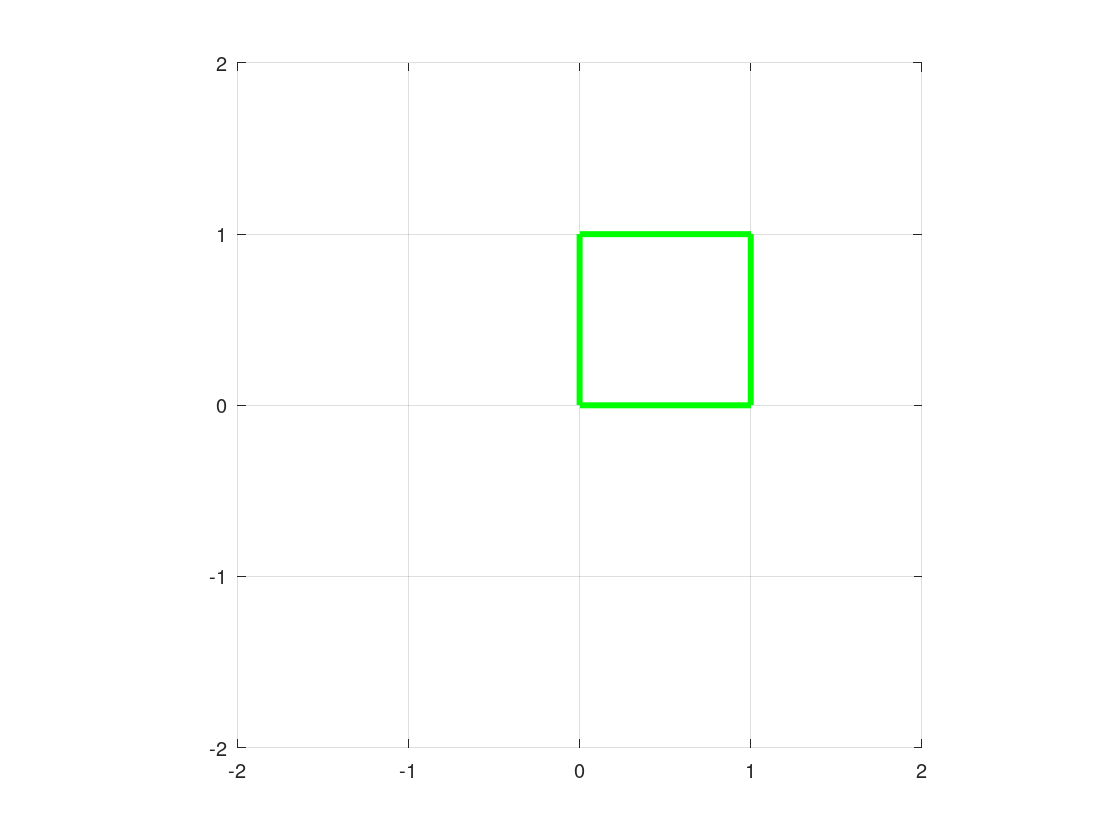

In [25]:
% Ejecutar esta celda. No modificar.
% Se crea un conjunto de puntos que forman un cuadrado al graficarse.


% ============================================================
% Definir puntos para formar un cuadrado.
%
% Observa que hay cinco puntos porque necesitamos volver
% al primer punto para completar el cuadrado al graficar
% con líneas conectadas.
% (0,0) → (0,1) → (1,1) → (1,0) → (0,0)
% ============================================================

% [x1 y1; x2 y2; ...; x5 y5]'
points = [0. 0.;
          0. 1.;
          1. 1.;
          1. 0.;
          0. 0.]';


% Después de la transposición, el arreglo points queda así:
%
% [x1 x2 ... x5;
%  y1 y2 ... y5]


% Coordenadas x extraídas del arreglo
x = points(1,:);


% Coordenadas y extraídas del arreglo
y = points(2,:);


% Graficar el arreglo de puntos en el mismo gráfico
% junto con un sistema de coordenadas
plot_2D(x, y, 'g', true);

### Aquí tenemos tres operaciones muy importantes sobre puntos:

### a) Traslación

La traslación significa:

$\begin{bmatrix}x'\\y'\end{bmatrix}=\begin{bmatrix}x\\y\end{bmatrix}+\begin{bmatrix}t_x\\t_y\end{bmatrix}$

donde $t_x$ y $t_y$ son constantes dadas.

Aquí, $x'$ representa una nueva coordenada $x$. No representa una transposición. Lo mismo aplica para $y'$.

---

### b) Rotación de un objeto por un ángulo dado

La rotación tendrá la siguiente forma:

$\begin{bmatrix}x'\\y'\end{bmatrix}=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}\begin{bmatrix}x\\y\end{bmatrix}$

donde $\theta$ es el ángulo mediante el cual deseamos rotar un conjunto de puntos en sentido antihorario.

---

### c) Escalamiento

El escalamiento modifica las coordenadas $x$ e $y$ de un conjunto de puntos para estirar o contraer un objeto, posiblemente en diferentes proporciones en las direcciones $x$ e $y$.

El escalamiento tiene la forma:

$\begin{bmatrix}x'\\y'\end{bmatrix}=\begin{bmatrix}S_x&0\\0&S_y\end{bmatrix}\begin{bmatrix}x\\y\end{bmatrix}$

---

Abordaremos estas operaciones una por una a continuación.

Lo primero que observamos es que la rotación y el escalamiento involucran multiplicación matriz-vector, mientras que la traslación involucra la suma de dos vectores.

Aunque la suma parece más simple que la multiplicación, mediante un uso algo “perverso” de las matemáticas, vamos a mostrarte cómo convertir también la traslación en una multiplicación matricial.

El resultado será una forma uniforme de representar estas tres operaciones, lo cual simplificará la manipulación de aproximadamente 185 MB de datos LiDAR.

## Parte A: La primera operación que realizaremos sobre nuestro cuadrado es trasladarlo. La operación matemática correspondiente se llama “traslación” (2 puntos)
  
  Trasladaremos cada punto en $-0.5$ en $x$ y $-0.5$ en $y$ para centrar el cuadrado alrededor del origen.  
- ### Tu tarea:
  
  Aplicar una traslación  
  
  $\begin{bmatrix}x\\y\end{bmatrix}\mapsto\begin{bmatrix}x\\y\end{bmatrix}+\begin{bmatrix}t_x\\t_y\end{bmatrix}$  
  
  a los puntos que forman el cuadrado utilizando suma de vectores.  
  
  Luego trabajaremos para realizar esta operación utilizando multiplicación matricial.  
  
  Aquí:  
  
  $\begin{bmatrix}t_x\\t_y\end{bmatrix}=\begin{bmatrix}-0.5\\-0.5\end{bmatrix}$  
  
  Guarda los puntos trasladados en un arreglo llamado `points2`.